In [62]:
%pip install -U "tensorflow==2.16.2" "tf-keras==2.16.0" "transformers==4.50.0" numpy pillow matplotlib

  Using cached numpy-2.5.3-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
Note: you may need to restart the kernel to use updated packages.


In [63]:
import os

os.environ["TF_USE_LEGACY_KERAS"] = "1"

In [64]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image

from transformers import (
    AutoTokenizer,
    TFCLIPModel
)

In [65]:
import torch

In [66]:
print("TensorFlow:", tf.__version__)

print(
    "GPUs:",
    tf.config.list_physical_devices("GPU")
)

print(
    "CPUs:",
    tf.config.list_physical_devices("CPU")
)

TensorFlow: 2.16.2
GPUs: []
CPUs: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [67]:
data = torch.load(
    "clip_test_embeddingsv2.pt",
    map_location="cpu"
)

np.savez_compressed(
    "clip_test_embeddings_tfv2.npz",
    features=data["features"].numpy(),
    labels=data["labels"].numpy()
)

In [68]:
MODEL_NAME = "openai/clip-vit-base-patch32"

print("Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print("Loading TensorFlow CLIP...")

clip_model = TFCLIPModel.from_pretrained(
    MODEL_NAME
)

print("CLIP loaded.")

Loading tokenizer...
Loading TensorFlow CLIP...


All model checkpoint layers were used when initializing TFCLIPModel.

All the layers of TFCLIPModel were initialized from the model checkpoint at openai/clip-vit-base-patch32.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFCLIPModel for predictions without further training.


CLIP loaded.


In [69]:
test_text = [
    "a chest X-ray showing pneumonia"
]

inputs = tokenizer(
    test_text,
    padding=True,
    truncation=True,
    return_tensors="tf"
)

text_features = clip_model.get_text_features(
    **inputs
)

print(
    "Text embedding shape:",
    text_features.shape
)

Text embedding shape: (1, 512)


In [70]:
NPZ_FILE = "clip_test_embeddings_tfv2.npz"

data = np.load(
    NPZ_FILE,
    allow_pickle=False
)
print(data)

NpzFile 'clip_test_embeddings_tfv2.npz' with keys: features, labels


In [71]:
TEST_DIR = r"C:\AI\Medical\Liver\data\stage1_balanced\test"

CLASSES = [
    "Pneumonia",
    "Corona Virus Disease",
    "Normal",
    "Tuberculosis"
]

image_paths = []

for class_name in CLASSES:

    class_dir = os.path.join(
        TEST_DIR,
        class_name
    )

    for filename in os.listdir(class_dir):

        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp")
        ):
            image_paths.append(
                os.path.join(
                    class_dir,
                    filename
                )
            )

print("Image embeddings:", image_embeddings.shape)
print("Image labels:", image_labels.shape)
print("Image paths:", len(image_paths))

Image embeddings: (2025, 512)
Image labels: (2025,)
Image paths: 1621


In [72]:
NPZ_FILE = "clip_test_embeddings_tf.npz"

data = np.load(
    NPZ_FILE,
    allow_pickle=False
)

image_embeddings = data["features"].astype(
    np.float32
)

image_labels = data["labels"].astype(
    np.int64
)

print(
    "Image embeddings:",
    image_embeddings.shape
)

print(
    "Labels:",
    image_labels.shape
)

print(
)

Image embeddings: (1621, 512)
Labels: (1621,)



In [73]:
path_labels = []

for class_name in CLASSES:

    class_dir = os.path.join(
        TEST_DIR,
        class_name
    )

    for filename in os.listdir(class_dir):

        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp")
        ):
            path_labels.append(
                CLASSES.index(class_name)
            )

print(
    "Labels match:",
    np.array_equal(
        np.array(path_labels),
        image_labels
    )
)

Labels match: True


In [74]:
CLASSES = [
    "Pneumonia",
    "Corona Virus Disease",
    "Normal",
    "Tuberculosis"
]

CLASS_TO_IDX = {
    name: i
    for i, name in enumerate(CLASSES)
}

IDX_TO_CLASS = {
    i: name
    for i, name in enumerate(CLASSES)
}

print(CLASS_TO_IDX)

{'Pneumonia': 0, 'Corona Virus Disease': 1, 'Normal': 2, 'Tuberculosis': 3}


In [75]:
image_embeddings_tf = tf.convert_to_tensor(
    image_embeddings,
    dtype=tf.float32
)

# Normalize
image_embeddings_tf = tf.math.l2_normalize(
    image_embeddings_tf,
    axis=1
)

print(
    "Tensor shape:",
    image_embeddings_tf.shape
)

Tensor shape: (1621, 512)


In [76]:
def get_text_embedding(query):

    inputs = tokenizer(
        [query],
        padding=True,
        truncation=True,
        return_tensors="tf"
    )

    text_features = clip_model.get_text_features(
        **inputs
    )

    text_features = tf.math.l2_normalize(
        text_features,
        axis=1
    )

    return text_features

In [77]:
def calculate_similarity(query):

    text_embedding = get_text_embedding(
        query
    )

    similarity = tf.matmul(
        image_embeddings_tf,
        text_embedding,
        transpose_b=True
    )

    similarity = tf.squeeze(
        similarity,
        axis=1
    )

    return similarity

In [78]:
def text_to_image_retrieval(
    query,
    top_k=5
):

    print(
        f'\nQuery: "{query}"'
    )

    similarities = calculate_similarity(
        query
    )

    top_values, top_indices = tf.math.top_k(
        similarities,
        k=top_k
    )

    top_values = top_values.numpy()
    top_indices = top_indices.numpy()

    fig, axes = plt.subplots(
        1,
        top_k,
        figsize=(4 * top_k, 5)
    )

    if top_k == 1:
        axes = [axes]

    for rank in range(top_k):

        idx = top_indices[rank]

        score = top_values[rank]

        image = Image.open(
            image_paths[idx]
        ).convert("RGB")

        axes[rank].imshow(
            image
        )

        axes[rank].axis("off")

        true_class = IDX_TO_CLASS[
            image_labels[idx]
        ]

        axes[rank].set_title(
            f"Rank {rank + 1}\n"
            f"Similarity: {score:.4f}\n"
            f"True: {true_class}"
        )

    plt.suptitle(
        f'Query: "{query}"',
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

    results = []

    for rank in range(top_k):

        idx = top_indices[rank]

        results.append({
            "rank": rank + 1,
            "image_path": image_paths[idx],
            "similarity": float(
                top_values[rank]
            ),
            "true_class": IDX_TO_CLASS[
                image_labels[idx]
            ]
        })

    return results


Query: "a chest X-ray showing pneumonia"


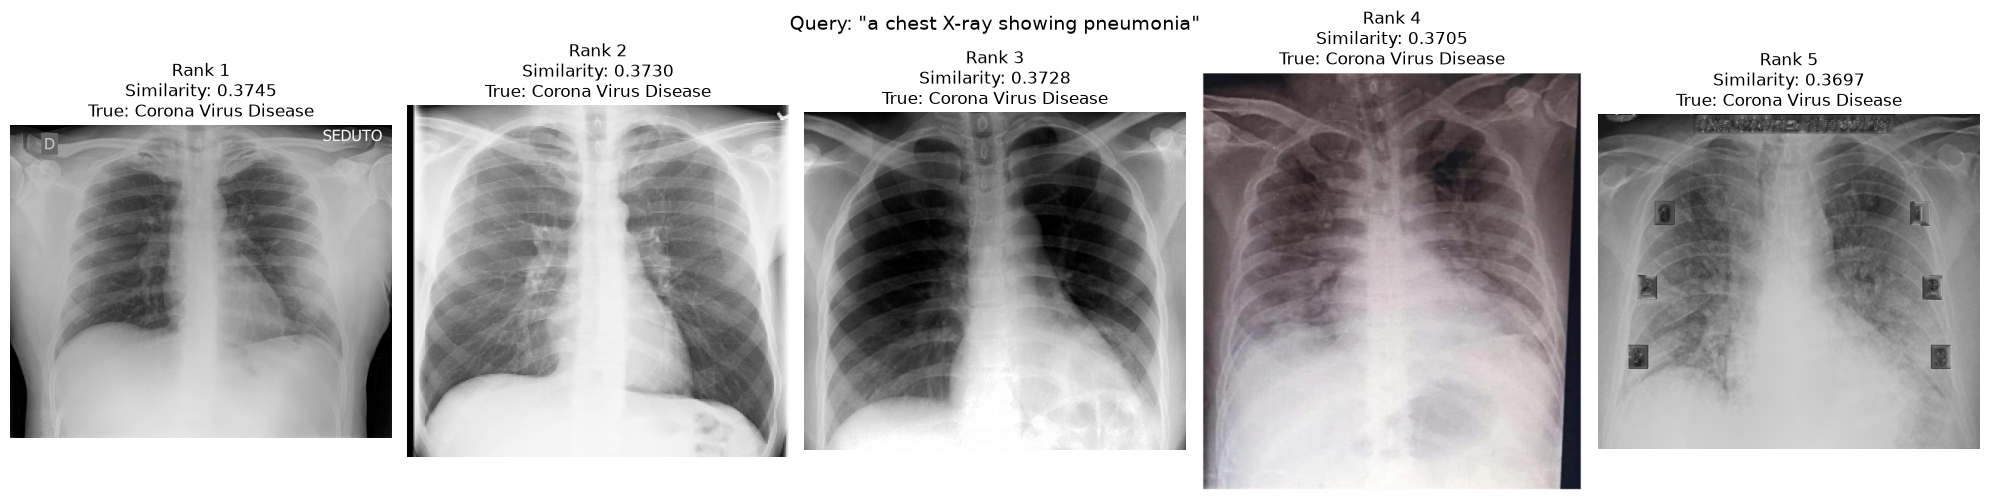

In [93]:
results = text_to_image_retrieval(
    "a chest X-ray showing pneumonia",
    top_k=5
)

In [80]:
for result in results:

    print(
        f"Rank {result['rank']} | "
        f"{result['similarity']:.4f} | "
        f"{result['true_class']} | "
        f"{result['image_path']}"
    )

Rank 1 | 0.3718 | Corona Virus Disease | C:\AI\Medical\Liver\data\stage1_balanced\test\Corona Virus Disease\COVID19(496).jpg
Rank 2 | 0.3716 | Corona Virus Disease | C:\AI\Medical\Liver\data\stage1_balanced\test\Corona Virus Disease\COVID19(67).jpg
Rank 3 | 0.3715 | Corona Virus Disease | C:\AI\Medical\Liver\data\stage1_balanced\test\Corona Virus Disease\1.CXRCTThoraximagesofCOVID-19fromSingapore.pdf-003-fig4b.png
Rank 4 | 0.3711 | Corona Virus Disease | C:\AI\Medical\Liver\data\stage1_balanced\test\Corona Virus Disease\COVID19(148).jpg
Rank 5 | 0.3703 | Tuberculosis | C:\AI\Medical\Liver\data\stage1_balanced\test\Tuberculosis\Tuberculosis-602.jpg



Query: "a chest X-ray showing viral pneumonia"


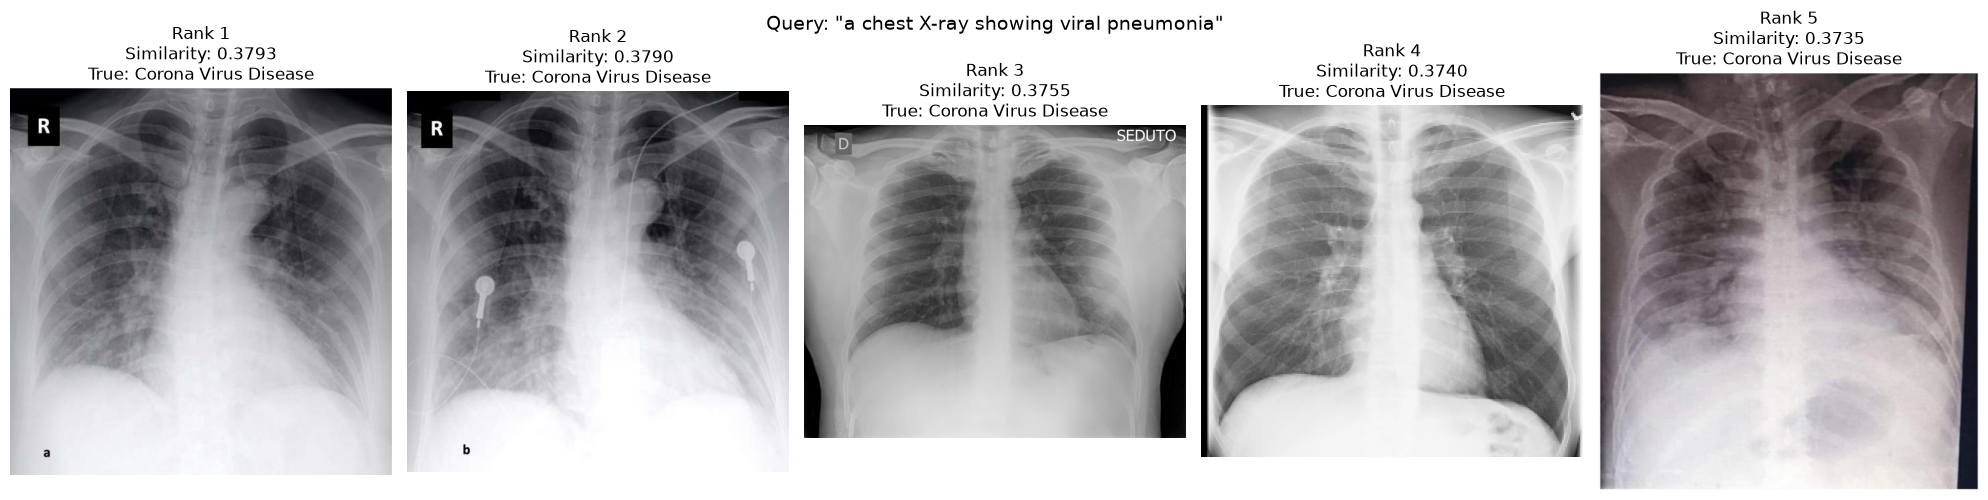

[{'rank': 1,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(50).jpg',
  'similarity': 0.3793346881866455,
  'true_class': 'Corona Virus Disease'},
 {'rank': 2,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\1.CXRCTThoraximagesofCOVID-19fromSingapore.pdf-003-fig4b.png',
  'similarity': 0.3790385127067566,
  'true_class': 'Corona Virus Disease'},
 {'rank': 3,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(496).jpg',
  'similarity': 0.37545472383499146,
  'true_class': 'Corona Virus Disease'},
 {'rank': 4,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\00030514_000.png',
  'similarity': 0.37404605746269226,
  'true_class': 'Corona Virus Disease'},
 {'rank': 5,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(148).jpg',
  'similarity': 0.373547226

In [81]:
text_to_image_retrieval(
    "a chest X-ray showing pneumonia",
    top_k=5
)


Query: "a chest X-ray showing COVID-19 related lung abnormalities"


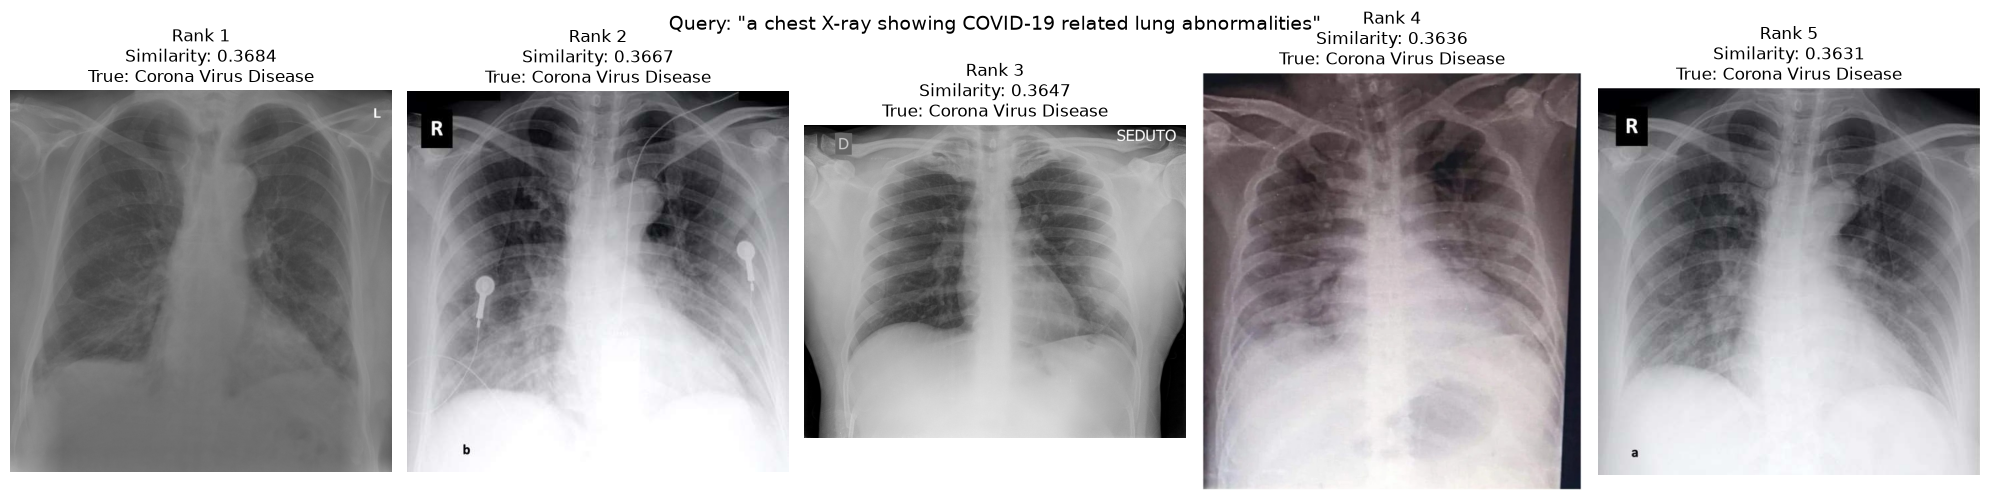

[{'rank': 1,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(154).jpg',
  'similarity': 0.36836326122283936,
  'true_class': 'Corona Virus Disease'},
 {'rank': 2,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\1.CXRCTThoraximagesofCOVID-19fromSingapore.pdf-003-fig4b.png',
  'similarity': 0.3666914701461792,
  'true_class': 'Corona Virus Disease'},
 {'rank': 3,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(496).jpg',
  'similarity': 0.36467504501342773,
  'true_class': 'Corona Virus Disease'},
 {'rank': 4,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(148).jpg',
  'similarity': 0.3636065125465393,
  'true_class': 'Corona Virus Disease'},
 {'rank': 5,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(50).jpg',
  'similarity': 0.363053023

In [82]:
text_to_image_retrieval(
    "a chest X-ray showing COVID-19 related lung abnormalities",
    top_k=5
)


Query: "a normal chest X-ray with clear lungs"


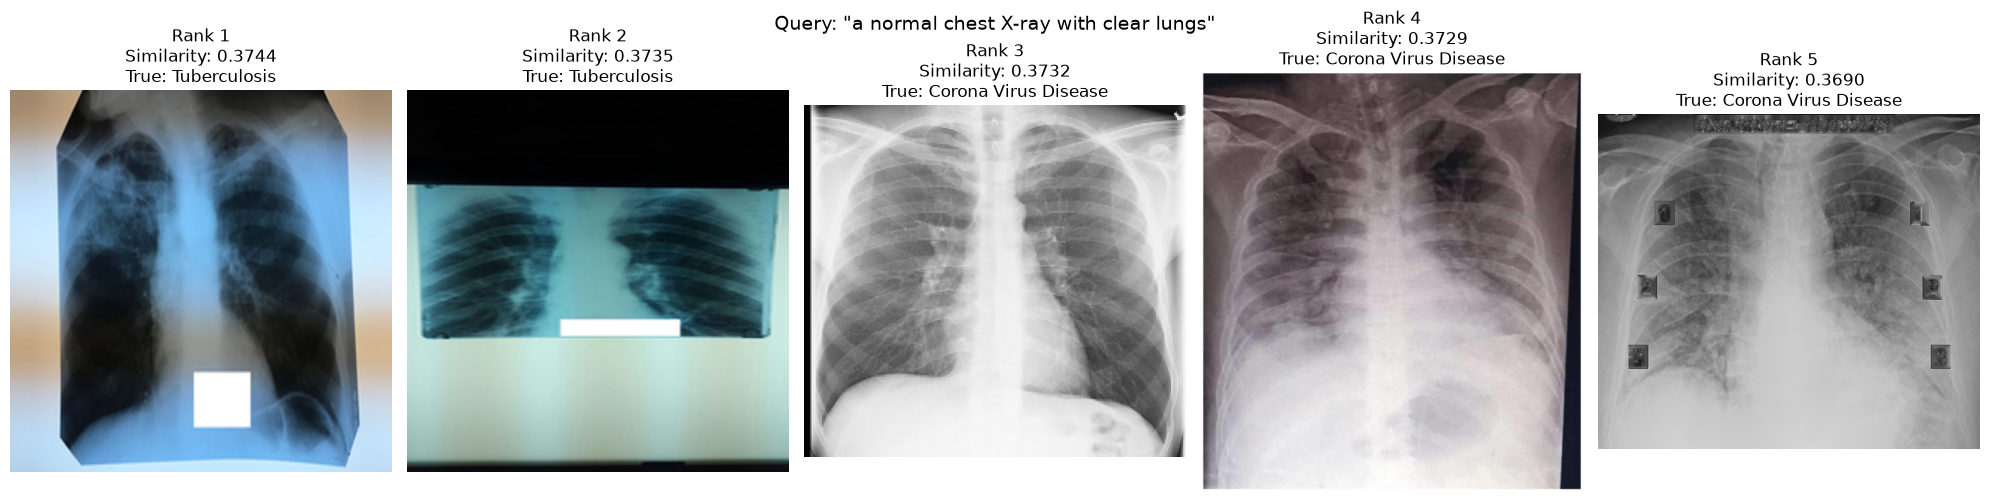

[{'rank': 1,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Tuberculosis\\Tuberculosis-588.jpg',
  'similarity': 0.37441492080688477,
  'true_class': 'Tuberculosis'},
 {'rank': 2,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Tuberculosis\\Tuberculosis-584.jpg',
  'similarity': 0.3735336363315582,
  'true_class': 'Tuberculosis'},
 {'rank': 3,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\00030514_000.png',
  'similarity': 0.3732450306415558,
  'true_class': 'Corona Virus Disease'},
 {'rank': 4,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(148).jpg',
  'similarity': 0.37294071912765503,
  'true_class': 'Corona Virus Disease'},
 {'rank': 5,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(67).jpg',
  'similarity': 0.36896243691444397,
  'true_class': 'Corona Virus Disease'}]

In [83]:
text_to_image_retrieval(
    "a normal chest X-ray with clear lungs",
    top_k=5
)


Query: "a chest X-ray showing pneumonia"


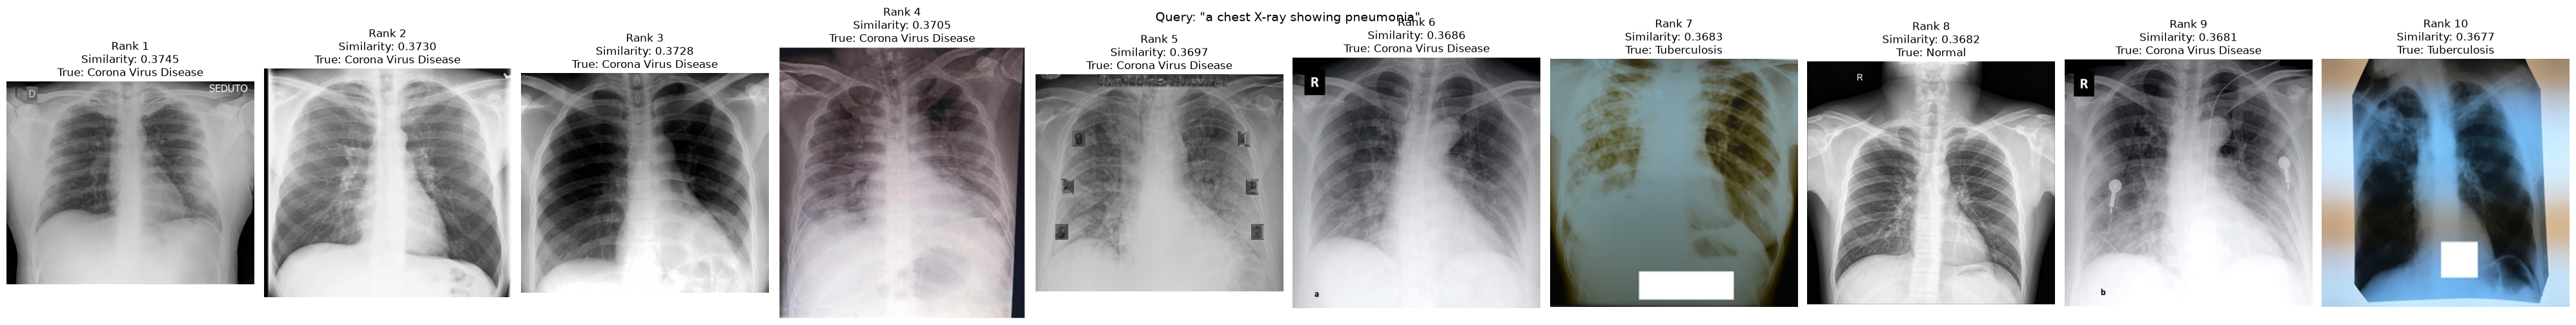

[{'rank': 1,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(496).jpg',
  'similarity': 0.3745200037956238,
  'true_class': 'Corona Virus Disease'},
 {'rank': 2,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\00030514_000.png',
  'similarity': 0.3729782700538635,
  'true_class': 'Corona Virus Disease'},
 {'rank': 3,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\054.jpeg',
  'similarity': 0.37278053164482117,
  'true_class': 'Corona Virus Disease'},
 {'rank': 4,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(148).jpg',
  'similarity': 0.37052780389785767,
  'true_class': 'Corona Virus Disease'},
 {'rank': 5,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(67).jpg',
  'similarity': 0.36968889832496643,
  'true_class': 'Corona Virus Disease'},
 

In [84]:
text_to_image_retrieval(
    "a chest X-ray showing pneumonia",
    top_k=10
)

In [85]:
PROMPTS = [
    "a chest X-ray showing bacterial pneumonia",
    "a chest X-ray showing COVID-19",
    "a normal chest X-ray with clear lungs",
    "a chest X-ray showing tuberculosis",
    "a chest X-ray showing viral pneumonia"
]

print(
    "Number of prompts:",
    len(PROMPTS)
)

Number of prompts: 5



Query: "lung infection caused by a virus on a chest X-ray"


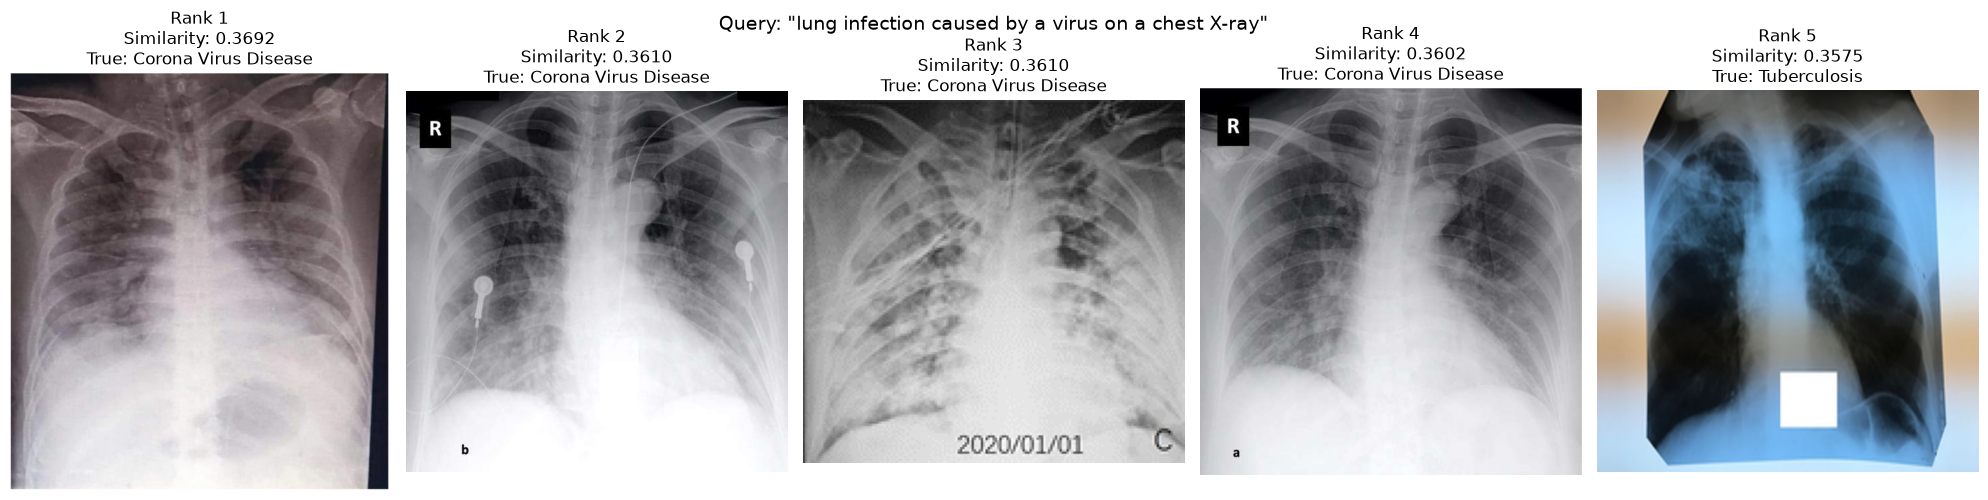

[{'rank': 1,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(148).jpg',
  'similarity': 0.3691895008087158,
  'true_class': 'Corona Virus Disease'},
 {'rank': 2,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\1.CXRCTThoraximagesofCOVID-19fromSingapore.pdf-003-fig4b.png',
  'similarity': 0.3610449433326721,
  'true_class': 'Corona Virus Disease'},
 {'rank': 3,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\ryct.2020003.fig2-c.png',
  'similarity': 0.36102473735809326,
  'true_class': 'Corona Virus Disease'},
 {'rank': 4,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Corona Virus Disease\\COVID19(50).jpg',
  'similarity': 0.36021071672439575,
  'true_class': 'Corona Virus Disease'},
 {'rank': 5,
  'image_path': 'C:\\AI\\Medical\\Liver\\data\\stage1_balanced\\test\\Tuberculosis\\Tuberculosis-588.jpg',
  'similarity': 0.357450

In [86]:
text_to_image_retrieval(
    "lung infection caused by a virus on a chest X-ray",
    top_k=5
)

In [87]:
inputs = tokenizer(
    PROMPTS,
    padding=True,
    truncation=True,
    return_tensors="tf"
)

text_features = clip_model.get_text_features(
    **inputs
)

text_features = tf.math.l2_normalize(
    text_features,
    axis=1
)

print(
    "Text embeddings:",
    text_features.shape
)

Text embeddings: (5, 512)


In [88]:
similarity_matrix = tf.matmul(
    image_embeddings_tf,
    text_features,
    transpose_b=True
)

print(
    "Similarity matrix:",
    similarity_matrix.shape
)

Similarity matrix: (1621, 5)


In [89]:
zero_shot_predictions = tf.argmax(
    similarity_matrix,
    axis=1
).numpy()

true_labels = image_labels

zero_shot_accuracy = np.mean(
    zero_shot_predictions == true_labels
)

print(
    f"Zero-shot accuracy: "
    f"{zero_shot_accuracy * 100:.2f}%"
)

Zero-shot accuracy: 13.51%


In [90]:
%pip install --force-reinstall "numpy==1.26.4" "scipy==1.13.1" "scikit-learn==1.5.2"

  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached scipy-1.13.1-cp312-cp312-win_amd64.whl.metadata (60 kB)
  Using cached scikit_learn-1.5.2-cp312-cp312-win_amd64.whl.metadata (13 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
Using cached scipy-1.13.1-cp312-cp312-win_amd64.whl (45.9 MB)
Using cached scikit_learn-1.5.2-cp312-cp312-win_amd64.whl (11.0 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

  Attempting uninstall: threadpoolctl

    Found existing installation: threadpoolctl 3.7.0

    Uninstalling threadpoolctl-3.7.0:

   ---------------------------------------- 0/6 [threadpoolctl]
   -----------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.


In [91]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [97]:
# Match prompt count to class count: 4 prompts for 4 classes
PROMPTS = [
    "a chest X-ray showing pneumonia",
    "a chest X-ray showing COVID-19 related lung abnormalities",
    "a normal chest X-ray with clear lungs",
    "a chest X-ray showing tuberculosis"
]

inputs = tokenizer(
    PROMPTS,
    padding=True,
    truncation=True,
    return_tensors="tf"
)

text_features = clip_model.get_text_features(
    **inputs
)

text_features = tf.math.l2_normalize(
    text_features,
    axis=1
)

similarity_matrix = tf.matmul(
    image_embeddings_tf,
    text_features,
    transpose_b=True
)

zero_shot_predictions = tf.argmax(
    similarity_matrix,
    axis=1
).numpy()

print(
    classification_report(
        true_labels,
        zero_shot_predictions,
        target_names=CLASSES,
    )
)

                      precision    recall  f1-score   support

           Pneumonia       0.27      0.62      0.38       402
Corona Virus Disease       0.72      0.25      0.37       407
              Normal       0.12      0.08      0.10       404
        Tuberculosis       0.12      0.09      0.10       408

            accuracy                           0.26      1621
           macro avg       0.31      0.26      0.24      1621
        weighted avg       0.31      0.26      0.24      1621



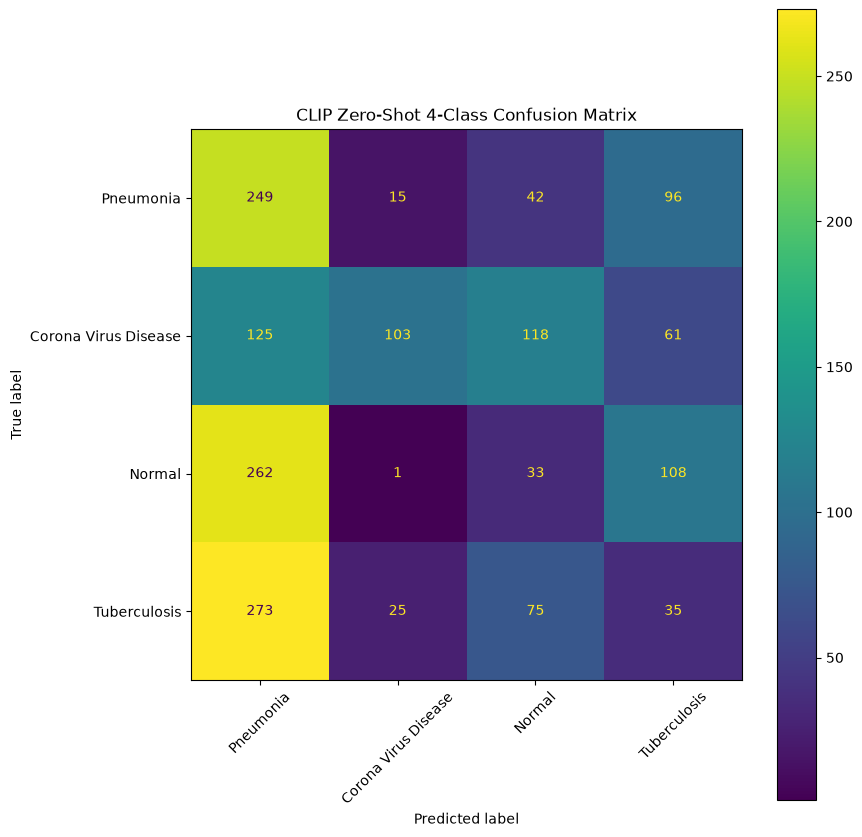

In [99]:
cm = confusion_matrix(
    true_labels,
    zero_shot_predictions
)

fig, ax = plt.subplots(
    figsize=(9, 9)
)

disp = ConfusionMatrixDisplay(                  
    confusion_matrix=cm,
    display_labels=CLASSES
)

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    "CLIP Zero-Shot 4-Class Confusion Matrix"
)

plt.tight_layout()
plt.show()